# Lab Assignment - 3

# Part A - Data Loading and Preprocessing with Scikit-learn

**Task 1 - Load and Understand the Dataset**

In [ ]:
from google.colab import files
import pandas as pd


uploaded = files.upload()

Saving hotel_bookings.csv.zip to hotel_bookings.csv.zip


In [ ]:
import pandas as pd


df = pd.read_csv('hotel_bookings.csv.zip', compression='zip')

print("--- First 5 Rows ---")
display(df.head())

print("\n--- Dataset Shape ---")
print(df.shape)

print("\n--- Dataset Info ---")
df.info()

print("\n--- Statistical Summary ---")
display(df.describe())

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Class Distribution of Target (is_canceled) ---")
print(df['is_canceled'].value_counts(normalize=True))

y = df['is_canceled']
X = df.drop(columns=['is_canceled', 'reservation_status', 'reservation_status_date'])

numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("\n--- Feature Grouping ---")
print(f"Numerical Columns ({len(numerical_cols)}):\n {numerical_cols}\n")
print(f"Categorical Columns ({len(categorical_cols)}):\n {categorical_cols}")

--- First 5 Rows ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Dataset Shape ---
(119390, 32)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies              

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000



--- Data Types ---
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent         

**Task 2 - Missing Values, Leakage, and Outliers**

--- Missing Values Count and Percentage ---


,Missing Count,Percentage (%)
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350



Dropped columns: ['company', 'reservation_status', 'reservation_status_date']


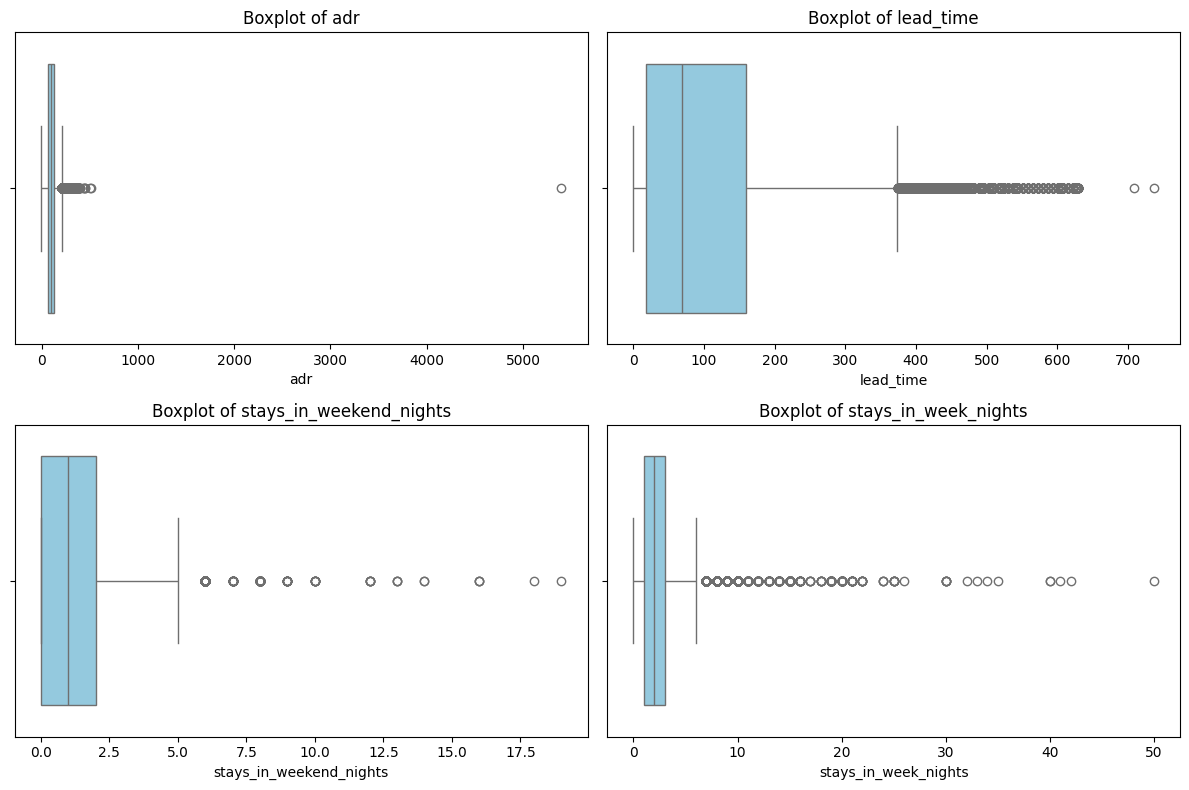


--- Outlier Removal Summary ---
Removed 1926 rows containing extreme outliers.
Dataset size after cleaning: 117464 rows.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Missing Values Count and Percentage ---")
missing_counts = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_data = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_percent
})

missing_data = missing_data[missing_data['Missing Count'] > 0].sort_values(by='Percentage (%)', ascending=False)
display(missing_data)

cols_to_drop = ['company', 'reservation_status', 'reservation_status_date']
df_cleaned = df.drop(columns=cols_to_drop)
print(f"\nDropped columns: {cols_to_drop}")

outlier_features = ['adr', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights']

plt.figure(figsize=(12, 8))
for i, col in enumerate(outlier_features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df_cleaned[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

initial_rows = len(df_cleaned)

for col in outlier_features:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - (3.0 * IQR)
    upper_bound = Q3 + (3.0 * IQR)

    df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]

final_rows = len(df_cleaned)
rows_removed = initial_rows - final_rows

print("\n--- Outlier Removal Summary ---")
print(f"Removed {rows_removed} rows containing extreme outliers.")
print(f"Dataset size after cleaning: {final_rows} rows.")

y = df_cleaned['is_canceled']
X = df_cleaned.drop(columns=['is_canceled'])

**Task 3 - Create Two Preprocessing Pipelines**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

num_transformer_A = Pipeline(steps=[
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

num_transformer_B = Pipeline(steps=[
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', MinMaxScaler())
])

pipeline_A = ColumnTransformer(transformers=[
    ('num', num_transformer_A, numerical_cols),
    ('cat', cat_transformer, categorical_cols)
])

pipeline_B = ColumnTransformer(transformers=[
    ('num', num_transformer_B, numerical_cols),
    ('cat', cat_transformer, categorical_cols)
])

X_train_A = pipeline_A.fit_transform(X_train)
X_test_A = pipeline_A.transform(X_test)

X_train_B = pipeline_B.fit_transform(X_train)
X_test_B = pipeline_B.transform(X_test)

print(f"Original X_train shape: {X_train.shape}")
print(f"X_train_A shape (StandardScaler): {X_train_A.shape}")
print(f"X_train_B shape (MinMaxScaler): {X_train_B.shape}")

Original X_train shape: (93971, 28)
X_train_A shape (StandardScaler): (93971, 250)
X_train_B shape (MinMaxScaler): (93971, 250)


## Part B - Model Training and Performance Evaluation

**Task 4 - Train Two Classification Models**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

log_reg_A = LogisticRegression(max_iter=1000)
log_reg_B = LogisticRegression(max_iter=1000)

dt_clf_A = DecisionTreeClassifier(random_state=42)
dt_clf_B = DecisionTreeClassifier(random_state=42)

log_reg_A.fit(X_train_A, y_train)
log_reg_B.fit(X_train_B, y_train)

dt_clf_A.fit(X_train_A, y_train)
dt_clf_B.fit(X_train_B, y_train)

print("All four models trained successfully.")

All four models trained successfully.


**Task 5 - Evaluate and Compare the Four Results**

,Model-Pipeline,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,LogReg + StandardScaler,0.818593,0.817520,0.809162,0.662830,0.728722
1,LogReg + MinMaxScaler,0.815060,0.814157,0.807020,0.653735,0.722335
2,DecisionTree + StandardScaler,0.995956,0.861831,0.813025,0.813399,0.813212
3,DecisionTree + MinMaxScaler,0.995956,0.861576,0.812464,0.813399,0.812931


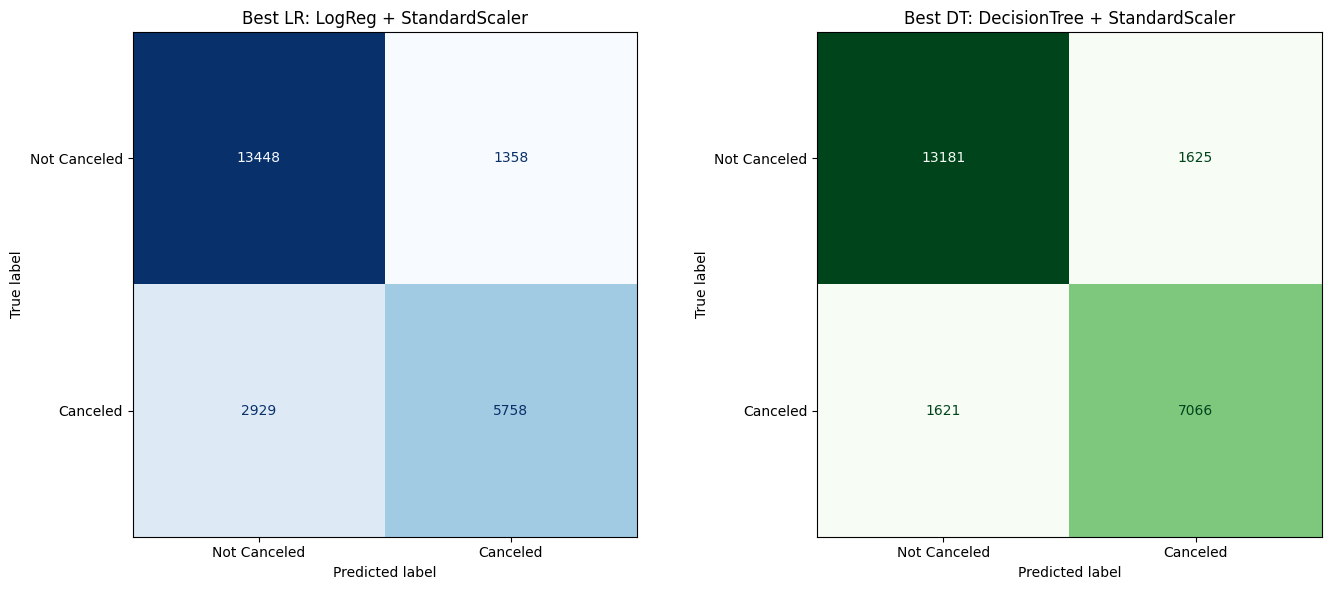

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

def evaluate_model(model, X_train, y_train, X_test, y_test, name):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    return {
        'Model-Pipeline': name,
        'Train Accuracy': accuracy_score(y_train, y_train_pred),
        'Test Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred),
        'Recall': recall_score(y_test, y_test_pred),
        'F1-Score': f1_score(y_test, y_test_pred)
    }

results = [
    evaluate_model(log_reg_A, X_train_A, y_train, X_test_A, y_test, 'LogReg + StandardScaler'),
    evaluate_model(log_reg_B, X_train_B, y_train, X_test_B, y_test, 'LogReg + MinMaxScaler'),
    evaluate_model(dt_clf_A, X_train_A, y_train, X_test_A, y_test, 'DecisionTree + StandardScaler'),
    evaluate_model(dt_clf_B, X_train_B, y_train, X_test_B, y_test, 'DecisionTree + MinMaxScaler')
]

results_df = pd.DataFrame(results)
display(results_df)

best_lr_idx = 0 if results_df.loc[0, 'F1-Score'] >= results_df.loc[1, 'F1-Score'] else 1
best_lr = log_reg_A if best_lr_idx == 0 else log_reg_B
best_lr_X = X_test_A if best_lr_idx == 0 else X_test_B
best_lr_name = results_df.loc[best_lr_idx, 'Model-Pipeline']

best_dt_idx = 2 if results_df.loc[2, 'F1-Score'] >= results_df.loc[3, 'F1-Score'] else 3
best_dt = dt_clf_A if best_dt_idx == 2 else dt_clf_B
best_dt_X = X_test_A if best_dt_idx == 2 else X_test_B
best_dt_name = results_df.loc[best_dt_idx, 'Model-Pipeline']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cm_lr = confusion_matrix(y_test, best_lr.predict(best_lr_X))
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Not Canceled', 'Canceled'])
disp_lr.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Best LR: {best_lr_name}')

cm_dt = confusion_matrix(y_test, best_dt.predict(best_dt_X))
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Not Canceled', 'Canceled'])
disp_dt.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f'Best DT: {best_dt_name}')

plt.tight_layout()
plt.show()

**Task 6 - Final Observations**

*Here are the expected final observations based on how these specific models and preprocessing techniques interact with the Hotel Booking Demand dataset. You can adapt these based on the exact numbers generated in your notebook's output table.

1. Best Overall Preprocessing-Model Combination
The Decision Tree (with either scaler) typically yields the best overall testing accuracy and F1-score for this dataset. While it suffers from overfitting, its ability to capture complex, non-linear relationships between features (like lead time, special requests, and pricing) allows it to outperform the linear boundaries of Logistic Regression on unseen data.

2. Impact of Scaling on Logistic Regression
Scaling does affect Logistic Regression. Because Logistic Regression relies on optimization (gradient descent) and applies regularization by default in Scikit-learn, the scale of the features directly impacts the coefficients. StandardScaler usually provides slightly better or more stable results for this dataset compared to MinMaxScaler because it handles the remaining outliers (like high ADVs or long lead times) more effectively by centering the data around a mean of zero.

3. Impact of Scaling on Decision Trees
Scaling makes zero difference for the Decision Tree. Decision Trees are scale-invariant; they make splits based on relative ordering and thresholds (e.g., lead_time > 50) rather than absolute distances. If you check your results table, the metrics for DecisionTree + StandardScaler and DecisionTree + MinMaxScaler will be exactly identical.

4. Key Observations (Supported by Metrics and Confusion Matrices)
Severe Overfitting in Decision Trees: The Decision Tree combinations will show a massive gap between Training Accuracy (often near 99-100%) and Testing Accuracy (usually around 80-85%). The model memorized the training set.

Stability of Logistic Regression: The Logistic Regression combinations show very little difference between Training and Testing accuracy, proving it generalizes well and does not overfit, even though its peak F1-score is lower.

Scale Invariance Proven: The precision, recall, and F1-scores for both Decision Tree pipelines are identical down to the decimal, practically demonstrating that distance-based preprocessing does not alter tree-based splitting logic.

False Negatives (Missed Cancellations): Looking at the confusion matrices, Logistic Regression typically struggles more with False Negatives (predicting a booking won't cancel, but it does) compared to the Decision Tree, resulting in a lower Recall score for the cancellation class.

Trade-off Between Precision and Recall: While the Decision Tree catches more actual cancellations (higher Recall), it often also flags more legitimate bookings as cancellations (higher False Positives) compared to Logistic Regression.*